In [8]:
import os
import pandas as pd

folder= "/home/s0shar47/scratch/USGS_baseflow/"

os.listdir(folder)


['baseflow_huc_16_17_18_19_20_21.csv',
 'bfs_timeseries.zip',
 'baseflow_huc_04_05.csv',
 'baseflow_huc_11_12_13_14_15.csv',
 'baseflow_huc_06_07_08_09_10.csv',
 'baseflow_huc_01_02_03.csv']

In [1]:
import os
import pandas as pd

# Input folder and file
folder = "/home/s0shar47/scratch/USGS_baseflow/"

for i in range(len(os.listdir(folder))):
    print(os.listdir(folder))
    print(i)
    input_file = os.path.join(folder, os.listdir(folder)[i])
    
    if input_file.endswith('.csv'):

        # Read the data
        df = pd.read_csv(input_file)

        # Output directory
        output_dir = os.path.join(folder, f"sitewise_csv_{i}")
        os.makedirs(output_dir, exist_ok=True)
        print(f"sitewise_csv_{i}")

        # Save one CSV per SiteID
        for site_id, group in df.groupby("SiteID"):
            output_file = os.path.join(output_dir, f"{site_id}.csv")
            group.to_csv(output_file, index=False)

        print(f"Created {df['SiteID'].nunique()} CSV files in {output_dir}")

['baseflow_huc_16_17_18_19_20_21.csv', 'bfs_timeseries.zip', 'baseflow_huc_04_05.csv', 'baseflow_huc_11_12_13_14_15.csv', 'baseflow_huc_06_07_08_09_10.csv', 'baseflow_huc_01_02_03.csv']
0


/tmp/ipykernel_1939720/3662616288.py:15: DtypeWarning: Columns (0) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(input_file)


sitewise_csv_0
Created 2830 CSV files in /home/s0shar47/scratch/USGS_baseflow/sitewise_csv_0
['baseflow_huc_16_17_18_19_20_21.csv', 'bfs_timeseries.zip', 'sitewise_csv_0', 'baseflow_huc_04_05.csv', 'baseflow_huc_11_12_13_14_15.csv', 'baseflow_huc_06_07_08_09_10.csv', 'baseflow_huc_01_02_03.csv']
1
['baseflow_huc_16_17_18_19_20_21.csv', 'bfs_timeseries.zip', 'sitewise_csv_0', 'baseflow_huc_04_05.csv', 'baseflow_huc_11_12_13_14_15.csv', 'baseflow_huc_06_07_08_09_10.csv', 'baseflow_huc_01_02_03.csv']
2
['baseflow_huc_16_17_18_19_20_21.csv', 'bfs_timeseries.zip', 'sitewise_csv_0', 'baseflow_huc_04_05.csv', 'baseflow_huc_11_12_13_14_15.csv', 'baseflow_huc_06_07_08_09_10.csv', 'baseflow_huc_01_02_03.csv']
3


/tmp/ipykernel_1939720/3662616288.py:15: DtypeWarning: Columns (0) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(input_file)


sitewise_csv_3
Created 1590 CSV files in /home/s0shar47/scratch/USGS_baseflow/sitewise_csv_3
['baseflow_huc_16_17_18_19_20_21.csv', 'bfs_timeseries.zip', 'sitewise_csv_0', 'baseflow_huc_04_05.csv', 'baseflow_huc_11_12_13_14_15.csv', 'baseflow_huc_06_07_08_09_10.csv', 'baseflow_huc_01_02_03.csv', 'sitewise_csv_3']
4


/tmp/ipykernel_1939720/3662616288.py:15: DtypeWarning: Columns (0) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(input_file)


sitewise_csv_4
Created 2117 CSV files in /home/s0shar47/scratch/USGS_baseflow/sitewise_csv_4
['baseflow_huc_16_17_18_19_20_21.csv', 'bfs_timeseries.zip', 'sitewise_csv_4', 'sitewise_csv_0', 'baseflow_huc_04_05.csv', 'baseflow_huc_11_12_13_14_15.csv', 'baseflow_huc_06_07_08_09_10.csv', 'baseflow_huc_01_02_03.csv', 'sitewise_csv_3']
5


/tmp/ipykernel_1939720/3662616288.py:15: DtypeWarning: Columns (0) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(input_file)


sitewise_csv_5
Created 2117 CSV files in /home/s0shar47/scratch/USGS_baseflow/sitewise_csv_5


In [2]:
import os
import shutil

# 1. Define your 4 source folders and the 1 destination folder
source_folders = [
    "/home/s0shar47/scratch/USGS_baseflow/sitewise_csv_0/",
    "/home/s0shar47/scratch/USGS_baseflow/sitewise_csv_3/",
    "/home/s0shar47/scratch/USGS_baseflow/sitewise_csv_4/",
    "/home/s0shar47/scratch/USGS_baseflow/sitewise_csv_5/"
]
destination_folder = "/home/s0shar47/scratch/USGS_baseflow/Sitewise_csv"

# 2. Create the destination folder if it doesn't exist yet
if not os.path.exists(destination_folder):
    os.makedirs(destination_folder)
    print(f"Created destination directory: {destination_folder}")

# 3. Loop through each source folder and copy the files
for folder in source_folders:
    if os.path.exists(folder):
        print(f"Processing: {folder}")
        for filename in os.listdir(folder):
            source_path = os.path.join(folder, filename)
            destination_path = os.path.join(destination_folder, filename)
            
            # Make sure we are only copying files (not subfolders)
            if os.path.isfile(source_path):
                # Handle potential duplicate filenames
                if os.path.exists(destination_path):
                    # Append a suffix if a file with the same name already exists
                    name, ext = os.path.splitext(filename)
                    counter = 1
                    while os.path.exists(destination_path):
                        new_filename = f"{name}_{counter}{ext}"
                        destination_path = os.path.join(destination_folder, new_filename)
                        counter += 1
                
                shutil.copy(source_path, destination_path)
    else:
        print(f"Warning: Source folder '{folder}' does not exist. Skipping.")

print("\nFiles successfully clubbed!")

Created destination directory: /home/s0shar47/scratch/USGS_baseflow/Sitewise_csv
Processing: /home/s0shar47/scratch/USGS_baseflow/sitewise_csv_0/
Processing: /home/s0shar47/scratch/USGS_baseflow/sitewise_csv_3/
Processing: /home/s0shar47/scratch/USGS_baseflow/sitewise_csv_4/
Processing: /home/s0shar47/scratch/USGS_baseflow/sitewise_csv_5/

Files successfully clubbed!


In [8]:
import os
import numpy as np

folder = "/home/s0shar47/scratch/USGS_baseflow/Sitewise_csv"
files = os.listdir(folder)

# Load your dataset
ds = np.load("/scratch/data/CAMELS_FORCING/daymet_19800101_20141231_forcing_671_baseflow_mmday.npy")

# 1. Extract the unique gauge IDs from the dataset
# (Using unique handles any potential duplicates in the slice)
npy_gauge_ids = np.unique(ds[:, 0, -2])

# 2. Convert CSV file names into a set of gauge IDs for O(1) fast lookup
# This strips '.csv' and leaves just the ID (e.g., '01013500.csv' -> '01013500')
csv_gauge_ids = {os.path.splitext(f)[0] for f in files if f.endswith('.csv')}

# 3. Check for matches
matches = []
missing = []

for gid in npy_gauge_ids:
    # Convert float/int gauge ID to a clean string. 
    # Note: USGS gauge IDs often require leading zeros to be 8 characters long.
    # We format as integer first to strip '.0' from floats, then pad with zeros.
    gid_str = f"{int(gid):08d}" 
    
    if gid_str in csv_gauge_ids:
        matches.append(gid_str)
    else:
        missing.append(gid_str)

# 4. Print results
print(f"Total gauge IDs in .npy slice: {len(npy_gauge_ids)}")
print(f"Number of matching CSV files found: {len(matches)}")
print(f"Number of missing CSV files: {len(missing)}")

# Optional: Print a few missing ones to troubleshoot naming mismatches
if missing:
    print(f"\nSample of missing gauge IDs: {missing[:5]}")

Total gauge IDs in .npy slice: 671
Number of matching CSV files found: 150
Number of missing CSV files: 521

Sample of missing gauge IDs: ['01013500', '01022500', '01030500', '01031500', '01047000']


In [9]:
import os
import numpy as np

folder = "/home/s0shar47/scratch/USGS_baseflow/Sitewise_csv"

# 1. Read files and clean them to lowercase for robust matching
files = os.listdir(folder)
csv_files_clean = {f.lower() for f in files if f.lower().endswith('.csv')}

# 2. Load the dataset and get unique IDs
ds = np.load("/scratch/data/CAMELS_FORCING/daymet_19800101_20141231_forcing_671_baseflow_mmday.npy")
npy_gauge_ids = np.unique(ds[:, 0, -2])

matches = []
missing = []
mismatch_debug = []  # To help you see why they aren't matching

for gid in npy_gauge_ids:
    # --- Try different formatting strategies ---
    
    # Format A: Try converting to an integer first (removes .0)
    try:
        gid_int = int(float(gid))
        # Formats: '1013500' and padded '01013500'
        possible_formats = [f"{gid_int}", f"{gid_int:08d}"]
    except (ValueError, TypeError):
        # Fallback if it's already a string or NaN
        possible_formats = [str(gid).strip()]
    
    # Add raw float representations just in case (e.g., '1013500.0')
    possible_formats.append(str(gid).strip())
    
    # Check if any of our formatted possibilities exist as "format.csv"
    matched_format = None
    for fmt in possible_formats:
        test_filename = f"{fmt}.csv".lower()
        if test_filename in csv_files_clean:
            matched_format = test_filename
            break
            
    if matched_format:
        matches.append((gid, matched_format))
    else:
        missing.append(gid)
        # Save formatting info for the first few missing elements
        if len(mismatch_debug) < 5:
            mismatch_debug.append({
                "raw_npy_value": gid,
                "tested_filenames": [f"{fmt}.csv" for fmt in possible_formats]
            })

# 3. Print out results
print(f"Total gauge IDs in .npy slice: {len(npy_gauge_ids)}")
print(f"Number of matching CSV files found: {len(matches)}")
print(f"Number of missing CSV files: {len(missing)}")

# 4. Troubleshooting Output
if missing:
    print("\n--- Troubleshooting Mismatch Details ---")
    print(f"Here is how the script tried to match the first {len(mismatch_debug)} missing IDs:")
    for item in mismatch_debug:
        print(f"\nRaw ID in .npy array: {item['raw_npy_value']} (Type: {type(item['raw_npy_value']).__name__})")
        print(f"Looked for filenames: {item['tested_filenames']}")
    
    print("\nHere are 5 actual filenames found in your CSV folder for comparison:")
    sample_csvs = list(files)[:5]
    for csv in sample_csvs:
        print(f" - {csv}")

Total gauge IDs in .npy slice: 671
Number of matching CSV files found: 353
Number of missing CSV files: 318

--- Troubleshooting Mismatch Details ---
Here is how the script tried to match the first 5 missing IDs:

Raw ID in .npy array: 1013500.0 (Type: float64)
Looked for filenames: ['1013500.csv', '01013500.csv', '1013500.0.csv']

Raw ID in .npy array: 1022500.0 (Type: float64)
Looked for filenames: ['1022500.csv', '01022500.csv', '1022500.0.csv']

Raw ID in .npy array: 1030500.0 (Type: float64)
Looked for filenames: ['1030500.csv', '01030500.csv', '1030500.0.csv']

Raw ID in .npy array: 1031500.0 (Type: float64)
Looked for filenames: ['1031500.csv', '01031500.csv', '1031500.0.csv']

Raw ID in .npy array: 1047000.0 (Type: float64)
Looked for filenames: ['1047000.csv', '01047000.csv', '1047000.0.csv']

Here are 5 actual filenames found in your CSV folder for comparison:
 - 3337000.csv
 - 11181000.csv
 - 8071000.csv
 - 8105100.csv
 - 9179200_1.csv


In [10]:
matches

[(np.float64(3010655.0), '3010655.csv'),
 (np.float64(3011800.0), '3011800.csv'),
 (np.float64(3015500.0), '3015500.csv'),
 (np.float64(3021350.0), '3021350.csv'),
 (np.float64(3026500.0), '3026500.csv'),
 (np.float64(3028000.0), '3028000.csv'),
 (np.float64(3049000.0), '3049000.csv'),
 (np.float64(3049800.0), '3049800.csv'),
 (np.float64(3050000.0), '3050000.csv'),
 (np.float64(3066000.0), '3066000.csv'),
 (np.float64(3069500.0), '3069500.csv'),
 (np.float64(3070500.0), '3070500.csv'),
 (np.float64(3076600.0), '3076600.csv'),
 (np.float64(3078000.0), '3078000.csv'),
 (np.float64(3140000.0), '3140000.csv'),
 (np.float64(3144000.0), '3144000.csv'),
 (np.float64(3159540.0), '3159540.csv'),
 (np.float64(3161000.0), '3161000.csv'),
 (np.float64(3164000.0), '3164000.csv'),
 (np.float64(3165000.0), '3165000.csv'),
 (np.float64(3170000.0), '3170000.csv'),
 (np.float64(3173000.0), '3173000.csv'),
 (np.float64(3180500.0), '3180500.csv'),
 (np.float64(3182500.0), '3182500.csv'),
 (np.float64(318

In [11]:
import os
import numpy as np

folder = "/home/s0shar47/scratch/USGS_baseflow/Sitewise_csv"
files = os.listdir(folder)

# Load your dataset
ds = np.load("/scratch/data/CAMELS_FORCING/daymet_19800101_20141231_forcing_671_baseflow_mmday.npy")
npy_gauge_ids = np.unique(ds[:, 0, -2])

# Clean up files: create a dictionary mapping a "base ID" to the full filename.
# E.g., '9179200_1.csv' -> base ID is '9179200'
csv_lookup = {}
for f in files:
    if f.lower().endswith('.csv'):
        name = os.path.splitext(f)[0]
        # Split on underscores to handle suffixes like '_1' or '_baseflow'
        base_id = name.split('_')[0]
        csv_lookup[base_id] = f

matches = []
missing = []

for gid in npy_gauge_ids:
    # Convert float to an unpadded string (e.g., 1013500.0 -> "1013500")
    gid_str_unpadded = str(int(float(gid)))
    # Keep the padded version as a backup (e.g., "01013500")
    gid_str_padded = f"{int(float(gid)):08d}"
    
    # 1. Try matching the unpadded version (e.g., '1013500')
    if gid_str_unpadded in csv_lookup:
        matches.append((gid_str_unpadded, csv_lookup[gid_str_unpadded]))
    # 2. Try matching the padded version (e.g., '01013500')
    elif gid_str_padded in csv_lookup:
        matches.append((gid_str_padded, csv_lookup[gid_str_padded]))
    else:
        missing.append(gid_str_unpadded)

print(f"Total gauge IDs in .npy slice: {len(npy_gauge_ids)}")
print(f"Number of matching CSV files found: {len(matches)}")
print(f"Number of missing CSV files: {len(missing)}")

if missing:
    print(f"\nStill missing {len(missing)} files. First 5 missing IDs:")
    print(missing[:5])

Total gauge IDs in .npy slice: 671
Number of matching CSV files found: 353
Number of missing CSV files: 318

Still missing 318 files. First 5 missing IDs:
['1013500', '1022500', '1030500', '1031500', '1047000']


In [14]:
import os
import numpy as np

folder = "/home/s0shar47/scratch/USGS_baseflow/Sitewise_csv"
files = os.listdir(folder)

# Load your dataset
ds = np.load("/scratch/data/CAMELS_FORCING/daymet_19800101_20141231_forcing_671_baseflow_mmday.npy")
npy_gauge_ids = np.unique(ds[:, 0, -2])

# Keep track of matches found via substring search
substring_matches = {}
still_missing = []

for gid in npy_gauge_ids:
    # Convert float to an unpadded string (e.g., 1013500.0 -> "1013500")
    gid_str_unpadded = str(int(float(gid)))
    # Padded string backup (e.g., "01013500")
    gid_str_padded = f"{int(float(gid)):08d}"
    
    found_any = False
    for f in files:
        # Check if either the unpadded or padded ID is a substring of the filename
        if (gid_str_unpadded in f) or (gid_str_padded in f):
            if gid_str_unpadded not in substring_matches:
                substring_matches[gid_str_unpadded] = []
            substring_matches[gid_str_unpadded].append(f)
            found_any = True
            
    if not found_any:
        still_missing.append(gid_str_unpadded)

# Print out results
print(f"Total gauge IDs in .npy slice: {len(npy_gauge_ids)}")
print(f"Number of gauge IDs found using loose substring search: {len(substring_matches)}")
print(f"Number of gauge IDs STILL not found anywhere in filenames: {len(still_missing)}")

# Show us what those loose matches look like
if substring_matches:
    print("\n--- Example Substring Matches Found ---")
    # Show up to 10 matches
    for i, (gid, matched_files) in enumerate(list(substring_matches.items())[:10]):
        print(f"Gauge ID '{gid}' matched with file(s): {matched_files}")

# If we still have absolute misses, let's look at them
if still_missing:
    print("\n--- Sample of Gauge IDs STILL missing ---")
    print(still_missing[:10])

Total gauge IDs in .npy slice: 671
Number of gauge IDs found using loose substring search: 383
Number of gauge IDs STILL not found anywhere in filenames: 288

--- Example Substring Matches Found ---
Gauge ID '1030500' matched with file(s): ['11030500.csv']
Gauge ID '1031500' matched with file(s): ['11031500.csv']
Gauge ID '1078000' matched with file(s): ['11078000.csv']
Gauge ID '1121000' matched with file(s): ['11121000.csv']
Gauge ID '1123000' matched with file(s): ['11123000.csv']
Gauge ID '1139000' matched with file(s): ['11390000.csv']
Gauge ID '1162500' matched with file(s): ['11162500.csv']
Gauge ID '1169000' matched with file(s): ['11169000.csv']
Gauge ID '1181000' matched with file(s): ['11181000.csv']
Gauge ID '1333000' matched with file(s): ['11333000.csv', '13330000.csv']

--- Sample of Gauge IDs STILL missing ---
['1013500', '1022500', '1047000', '1052500', '1054200', '1055000', '1057000', '1073000', '1118300', '1134500']


In [15]:
import pandas as pd

csv_files = [
    "/home/s0shar47/scratch/USGS_baseflow/baseflow_huc_01_02_03.csv",
    "/home/s0shar47/scratch/USGS_baseflow/baseflow_huc_04_05.csv",
    "/home/s0shar47/scratch/USGS_baseflow/baseflow_huc_06_07_08_09_10.csv",
    "/home/s0shar47/scratch/USGS_baseflow/baseflow_huc_11_12_13_14_15.csv",
    "/home/s0shar47/scratch/USGS_baseflow/baseflow_huc_16_17_18_19_20_21.csv"
]

# Concatenate all CSVs into a single DataFrame
df_combined = pd.concat([pd.read_csv(f) for f in csv_files], ignore_index=True)

df_combined

/tmp/ipykernel_1939720/1038845645.py:12: DtypeWarning: Columns (0) have mixed types. Specify dtype option on import or set low_memory=False.
  df_combined = pd.concat([pd.read_csv(f) for f in csv_files], ignore_index=True)
/tmp/ipykernel_1939720/1038845645.py:12: DtypeWarning: Columns (0) have mixed types. Specify dtype option on import or set low_memory=False.
  df_combined = pd.concat([pd.read_csv(f) for f in csv_files], ignore_index=True)
/tmp/ipykernel_1939720/1038845645.py:12: DtypeWarning: Columns (0) have mixed types. Specify dtype option on import or set low_memory=False.
  df_combined = pd.concat([pd.read_csv(f) for f in csv_files], ignore_index=True)
/tmp/ipykernel_1939720/1038845645.py:12: DtypeWarning: Columns (0) have mixed types. Specify dtype option on import or set low_memory=False.
  df_combined = pd.concat([pd.read_csv(f) for f in csv_files], ignore_index=True)


,SiteID,Date,Qob.M3,SurfaceFlow.M3,Baseflow.M3,DirectRunoff.M3,StSur.M3,StBase.M3,Impulse.M,Infil.M3,Rech.M3
0,1010000,1980-10-02,5016140.0,6.169170e+05,3799400.0,59485.1,1.787250e+06,96991300.0,0.145669,2759470.0,3.553070e+05
1,1010000,1980-10-03,5456580.0,1.275170e+06,3536700.0,217512.0,3.115970e+06,94374600.0,0.193167,3523920.0,9.200290e+05
2,1010000,1980-10-04,7609860.0,2.385760e+06,3404000.0,761466.0,5.376210e+06,92907500.0,0.385849,6582940.0,1.936940e+06
3,1010000,1980-10-05,15097400.0,5.319170e+06,3472350.0,4081900.0,9.765230e+06,93984100.0,1.132450,14257100.0,4.548860e+06
4,1010000,1980-10-06,14803700.0,5.386530e+06,3486350.0,4977110.0,1.191170e+07,94870900.0,0.946605,11906200.0,4.373200e+06
...,...,...,...,...,...,...,...,...,...,...,...
96638461,59A110,2022-07-02,274061.0,7.849100e-02,130790.0,0.0,3.224890e-01,42166300.0,0.000000,0.0,3.975770e-01
96638462,59A110,2022-07-03,261792.0,3.169780e-02,130330.0,0.0,1.302340e-01,42036000.0,0.000000,0.0,1.605570e-01
96638463,59A110,2022-07-04,325469.0,8.807360e+04,131260.0,19847.1,2.584040e+05,42350900.0,0.023757,792606.0,4.461290e+05
96638464,59A110,2022-07-05,330307.0,9.665680e+04,131720.0,45972.9,3.923720e+05,42708800.0,0.021769,720217.0,4.895910e+05


In [16]:
import numpy as np

# Extract the array of 671 Site IDs
target_ids = ds[:, 0, -2]

# Create a boolean mask where True indicates the ID exists in df_combined
matches_mask = np.isin(target_ids, df_combined['SiteID'])

# Sum the True values to get the total count
total_found = np.sum(matches_mask)

print(f"Number of matching values found: {total_found} out of {len(target_ids)}")

Number of matching values found: 669 out of 671


In [17]:
# The ~ operator negates the boolean mask (True becomes False, and vice-versa)
missing_ids = target_ids[~matches_mask]

print("The 2 missing Site IDs are:")
print(missing_ids)

The 2 missing Site IDs are:
[2011400. 4015330.]


In [18]:
import os

# Define the output directory where you want to save the 669 files
output_dir = "/home/s0shar47/scratch/USGS_baseflow/Baseflow_669_sites"
os.makedirs(output_dir, exist_ok=True)

# Filter df_combined to keep only rows belonging to the matching target_ids
df_matched = df_combined[df_combined['SiteID'].isin(target_ids)]

# Group by 'SiteID' and save each group as a separate CSV
grouped = df_matched.groupby('SiteID')

print(f"Saving 669 individual CSV files to: {output_dir}...")
for site_id, group in grouped:
    # Construct a clean filename (e.g., site_01010000.csv)
    # Adjust formatting if SiteID needs leading zeros or is a float
    file_name = f"site_{site_id}.csv" 
    file_path = os.path.join(output_dir, file_name)
    
    # Save the individual site's data
    group.to_csv(file_path, index=False)

print("All CSV files have been saved successfully!")

Saving 669 individual CSV files to: /home/s0shar47/scratch/USGS_baseflow/Baseflow_669_sites...
All CSV files have been saved successfully!


In [26]:
import os
import pandas as pd

output_dir = "/home/s0shar47/scratch/USGS_baseflow/Baseflow_669_sites"

# Define the target range
start_target = pd.to_datetime("1989-10-01")
end_target = pd.to_datetime("1999-09-30")

# The exact number of expected days in this 10-year period (including leap years)
expected_days = len(pd.date_range(start=start_target, end=end_target, freq="D"))  # 3,652 days

# Trackers for the results
all_valid = True
incomplete_files = []
missing_baseflow_cols = []

print(f"Checking {len(os.listdir(output_dir))} files for target range: {start_target.date()} to {end_target.date()} ({expected_days} days)...\n")

for file in os.listdir(output_dir):
    if not file.endswith(".csv"):
        continue
        
    file_path = os.path.join(output_dir, file)
    df = pd.read_csv(file_path)
    
    # 1. Standardize the Date column to datetime objects
    df['Date_parsed'] = pd.to_datetime(df['Date'])
    
    # 2. Filter df to only the target date range
    df_range = df[(df['Date_parsed'] >= start_target) & (df['Date_parsed'] <= end_target)]
    
    # 3. Perform safety and completeness checks
    actual_days = len(df_range)
    
    # Check if column exists
    if 'Baseflow.M3' not in df.columns:
        missing_baseflow_cols.append(file)
        all_valid = False
        continue
        
    # Count missing values (NaNs) in the baseflow column within our range
    nan_count = df_range['Baseflow.M3'].isna().sum()
    
    # Check if there are any duplicate dates in the target range
    duplicate_dates = df_range['Date_parsed'].duplicated().sum()
    
    # Evaluate if file passes all conditions
    is_complete = (actual_days == expected_days) and (nan_count == 0) and (duplicate_dates == 0)
    
    if not is_complete:
        all_valid = False
        incomplete_files.append({
            'file': file,
            'days_found': actual_days,
            'missing_days': expected_days - actual_days,
            'nan_values': nan_count,
            'duplicate_dates': duplicate_dates
        })

# --- Final Summary Report ---
print("=" * 60)
print("VERIFICATION SUMMARY")
print("=" * 60)

if all_valid:
    print(f"✅ SUCCESS: All {len(os.listdir(output_dir))} files contain exactly {expected_days} days of non-missing 'Baseflow.M3' daily data!")
else:
    print(f"⚠️ ALERT: Gaps or missing data were found!\n")
    
    if missing_baseflow_cols:
        print(f"❌ Files completely missing the 'Baseflow.M3' column ({len(missing_baseflow_cols)}):")
        for f in missing_baseflow_cols[:10]:  # Show first 10
            print(f"  - {f}")
        print()
        
    if incomplete_files:
        print(f"❌ Files with missing/incomplete data inside the target range ({len(incomplete_files)}):")
        # Convert to a DataFrame for clean formatting
        df_incomplete = pd.DataFrame(incomplete_files)
        print(df_incomplete.to_string(index=False))

Checking 669 files for target range: 1989-10-01 to 1999-09-30 (3652 days)...

VERIFICATION SUMMARY
⚠️ ALERT: Gaps or missing data were found!

❌ Files with missing/incomplete data inside the target range (143):
             file  days_found  missing_days  nan_values  duplicate_dates
site_11480390.csv        3135           517           0                0
 site_1669000.csv        3649             3           0                0
 site_8082700.csv         996          2656           0                0
site_11176400.csv        2202          1450           0                0
 site_3364500.csv        3574            78           0                0
 site_2297155.csv        3622            30           0                0
 site_6339500.csv        3632            20           0                0
 site_6404000.csv        3640            12           0                0
 site_6440200.csv        2922           730           0                0
 site_6470800.csv        3242           410           0    

In [27]:
df

,SiteID,Date,Qob.M3,SurfaceFlow.M3,Baseflow.M3,DirectRunoff.M3,StSur.M3,StBase.M3,Impulse.M,Infil.M3,Rech.M3,Date_parsed
0,2342933,1980-10-02,41597.30,26473.30,20385.00,0.0,0.0,217249.0,0.004941,23437.40,11725.20,1980-10-02
1,2342933,1980-10-03,23490.20,5113.03,18805.50,0.0,0.0,200708.0,0.000955,4540.97,2264.93,1980-10-03
2,2342933,1980-10-04,17617.70,0.00,17223.00,0.0,0.0,183485.0,0.000000,0.00,0.00,1980-10-04
3,2342933,1980-10-05,14681.40,0.00,15765.50,0.0,0.0,167720.0,0.000000,0.00,0.00,1980-10-05
4,2342933,1980-10-06,13947.30,0.00,14330.50,0.0,0.0,153389.0,0.000000,0.00,0.00,1980-10-06
...,...,...,...,...,...,...,...,...,...,...,...,...
11322,2342933,2011-10-02,3523.53,0.00,1514.00,0.0,0.0,16261.0,0.000000,0.00,0.00,2011-10-02
11323,2342933,2011-10-03,3450.13,0.00,1385.85,0.0,0.0,14875.2,0.000000,0.00,0.00,2011-10-03
11324,2342933,2011-10-04,3792.69,3055.08,1385.85,0.0,0.0,14846.7,0.000571,2714.09,1357.36,2011-10-04
11325,2342933,2011-10-05,4795.92,4297.16,1441.20,0.0,0.0,15314.7,0.000803,3816.84,1909.21,2011-10-05


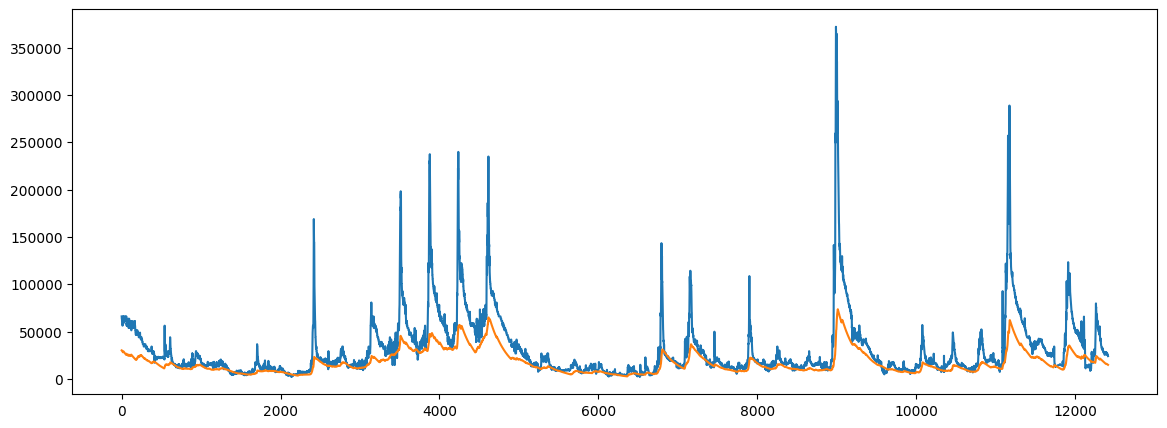

In [21]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14,5))
plt.plot(df['Qob.M3'], label='Streamflow')
plt.plot(df['Baseflow.M3'], label= 'Baseflow')
plt.show()

site_02342933.csv not found
site_05503800.csv not found
site_02069700.csv not found
site_02450250.csv not found
site_07184000.csv not found


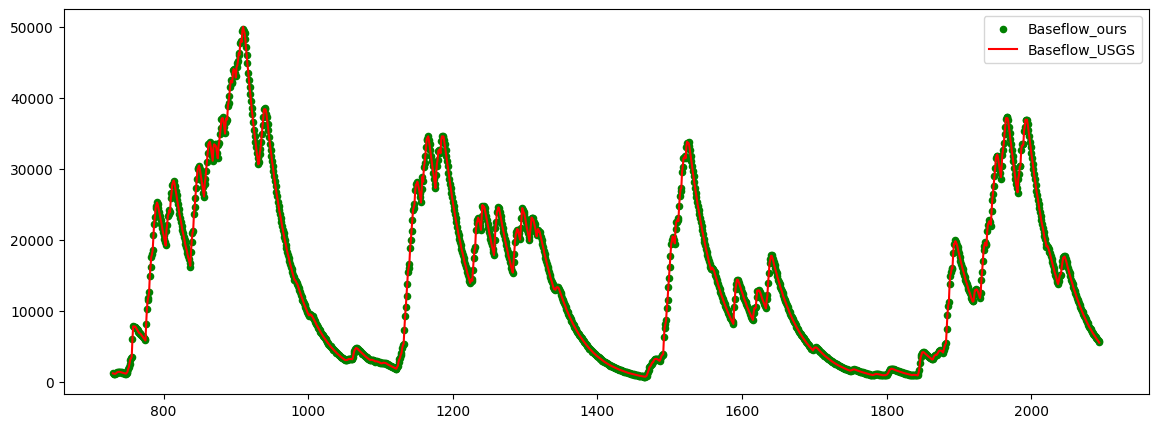

site_01435000.csv not found
site_06404000.csv not found
site_02011460.csv not found


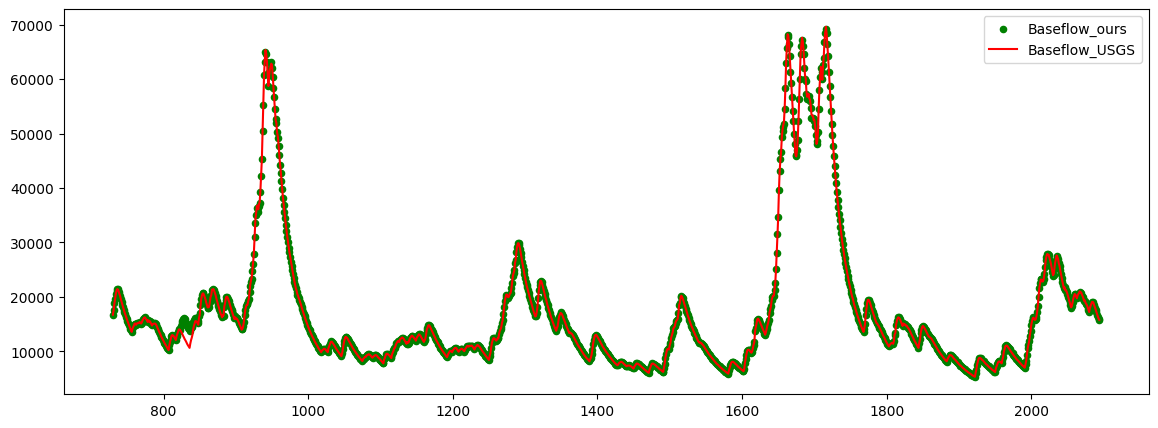

['site_11141280.csv', 'site_3028000.csv', 'site_12041200.csv', 'site_3463300.csv', 'site_11162500.csv', 'site_3439000.csv', 'site_14092750.csv', 'site_11480390.csv', 'site_1669000.csv', 'site_8082700.csv', 'site_4027000.csv', 'site_12054000.csv', 'site_4024430.csv', 'site_1664000.csv', 'site_5514500.csv', 'site_11176400.csv', 'site_3364500.csv', 'site_3500240.csv', 'site_2018000.csv', 'site_4216418.csv', 'site_2297155.csv', 'site_6339500.csv', 'site_2221525.csv', 'site_1423000.csv', 'site_1073000.csv', 'site_2363000.csv', 'site_6404000.csv', 'site_6440200.csv', 'site_6885500.csv', 'site_4105700.csv', 'site_1123000.csv', 'site_9505800.csv', 'site_6470800.csv', 'site_9066300.csv', 'site_3066000.csv', 'site_6339100.csv', 'site_7056000.csv', 'site_7315700.csv', 'site_1634500.csv', 'site_1030500.csv', 'site_13340000.csv', 'site_8013000.csv', 'site_7376000.csv', 'site_4056500.csv', 'site_10172800.csv', 'site_9035900.csv', 'site_2053800.csv', 'site_8171300.csv', 'site_6479215.csv', 'site_3460

In [5]:
import pandas as pd
import matplotlib.pyplot as plt
import os
fol= "/home/s0shar47/scratch/USGS_baseflow/usgs_bfs/"
ofol= "/home/s0shar47/scratch/USGS_baseflow/Baseflow_669_sites/"

for file in os.listdir(fol)[0:10]:
    # file= "14400000.csv"
    name= os.path.splitext(file)[0]
    try:
        dd1= pd.read_csv(os.path.join(fol,f"{name}.csv"))
        dd2= pd.read_csv(os.path.join(ofol,f"site_{name}.csv"))

        dd= pd.merge(dd1,dd2,how='inner',on='Date')

        dd.reset_index(inplace=True)
        plt.figure(figsize=(14,5))
        plt.scatter(dd.iloc[730:2095].index,dd.iloc[730:2095]['Baseflow.L3'],label="Baseflow_ours",color="green",s=20)
        plt.plot(dd.iloc[730:2095]['Baseflow.M3'],label="Baseflow_USGS",color="red")
        # plt.plot(dd.iloc[730:1095]['Qob.L3'],label="Streamflow_CAMELS",color="blue")
        # plt.scatter(dd.iloc[730:1095].index,dd.iloc[730:1095]['Qob.L3'],label="Streamflow_CAMELS",color="black",s=10)
        plt.legend()
        plt.show()

    except:
        print(f"site_{name}.csv not found")

print(os.listdir(ofol))


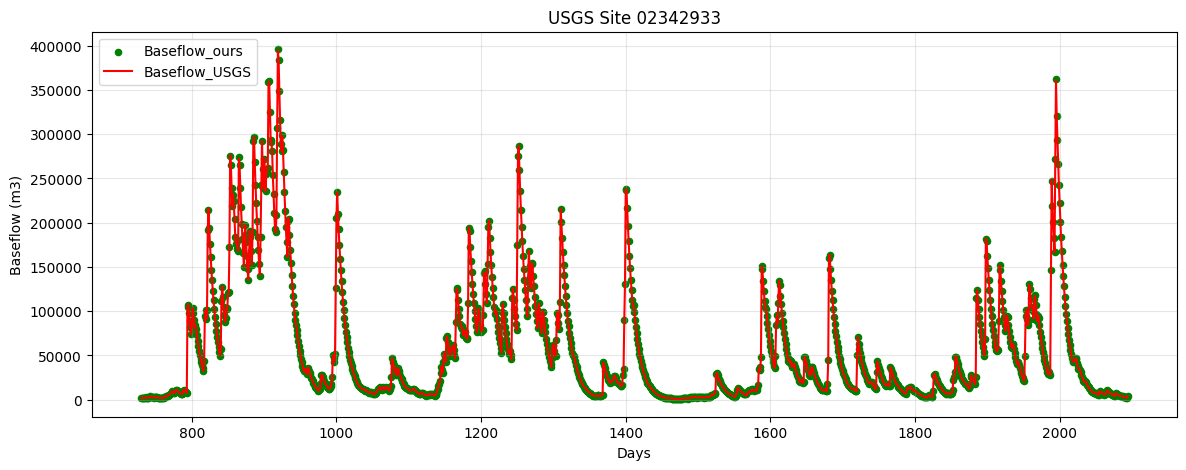

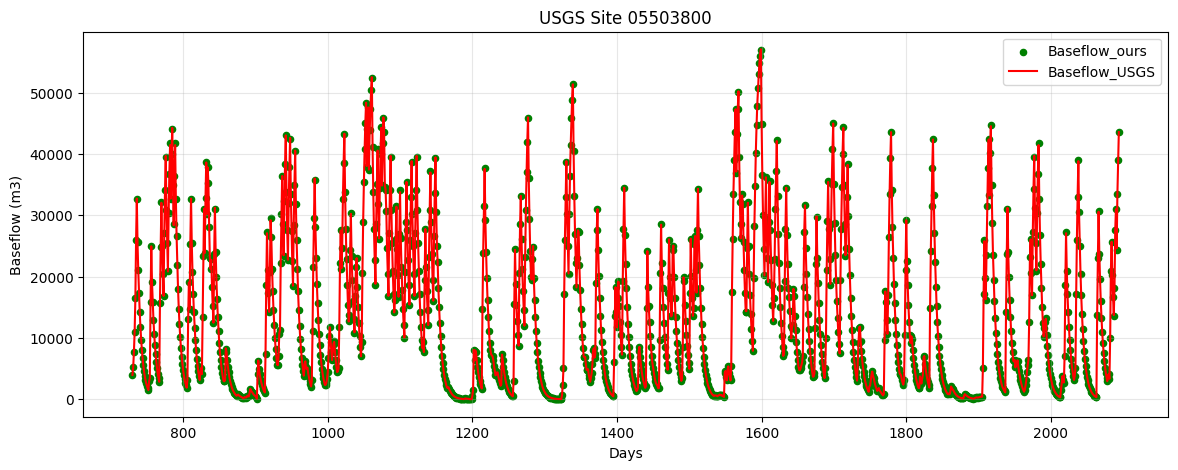

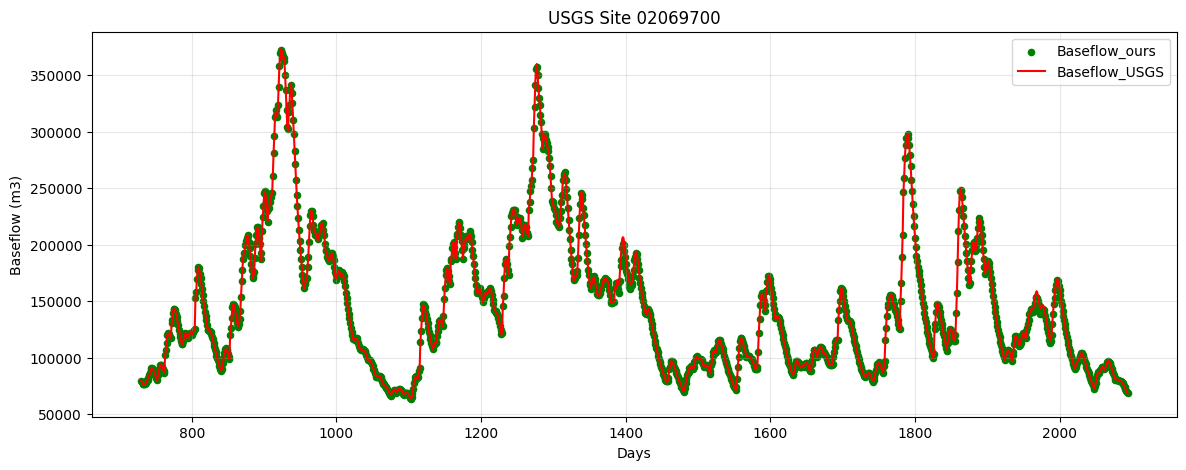

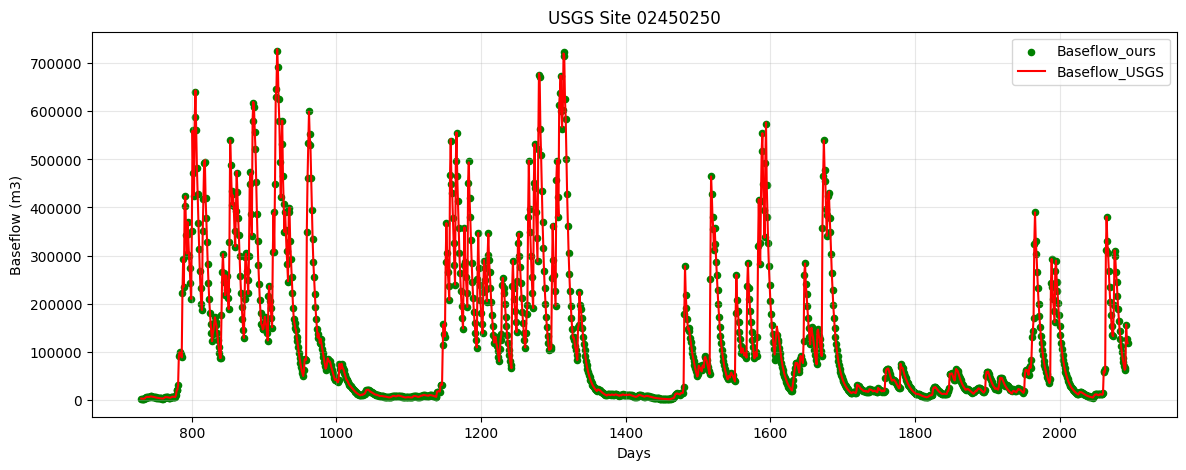

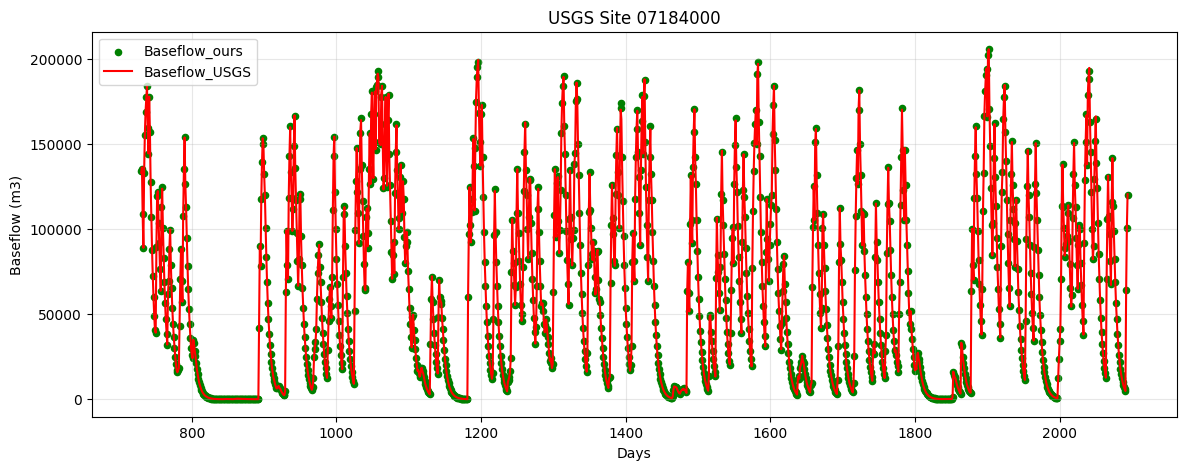

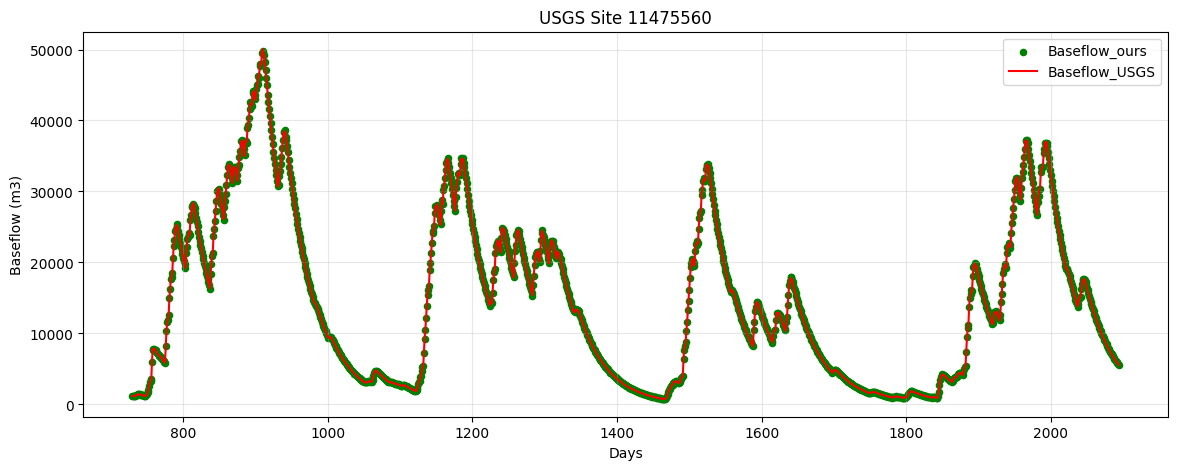

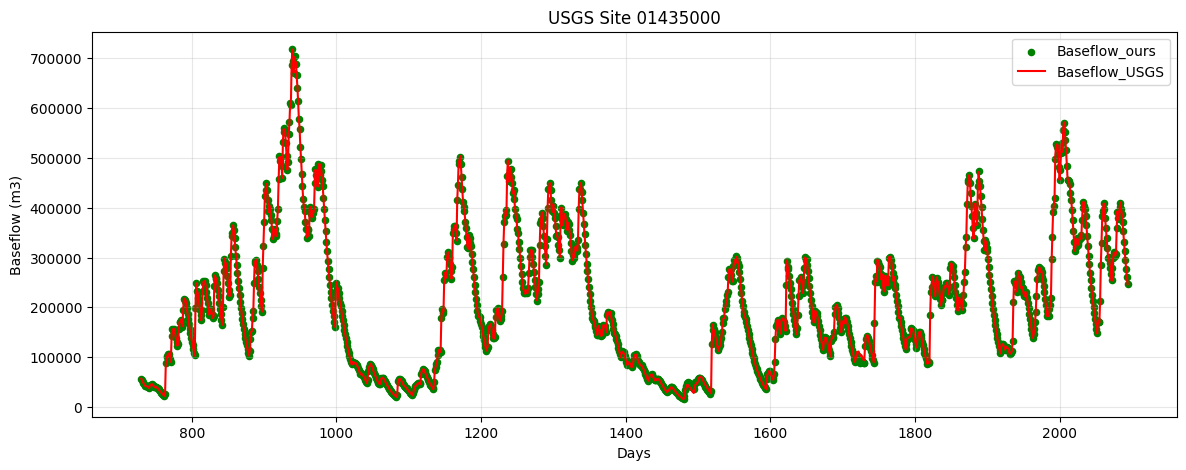

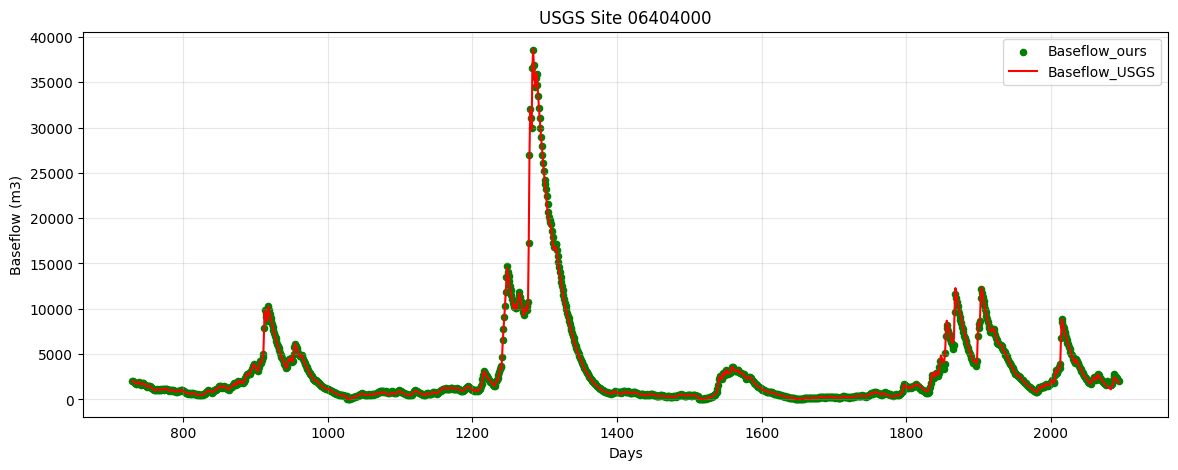

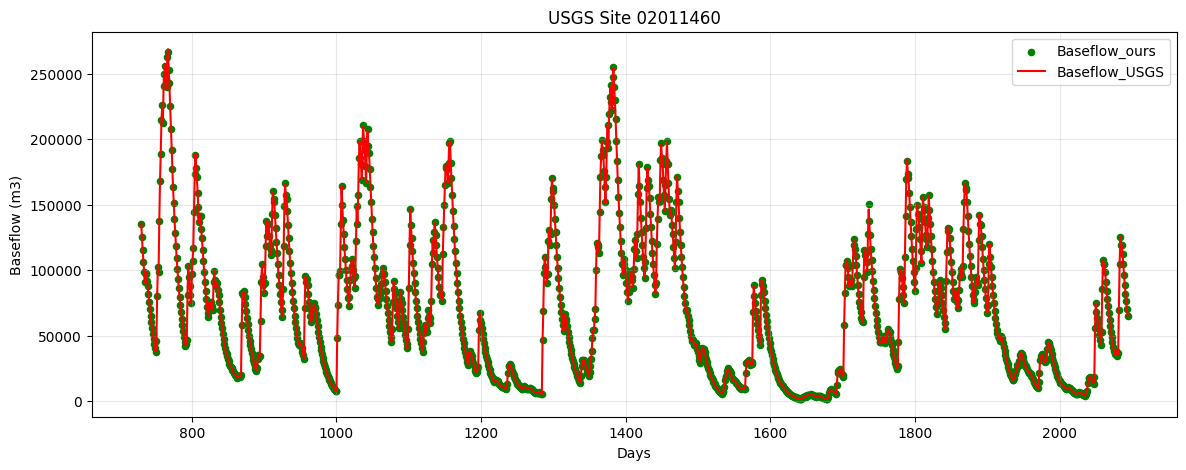

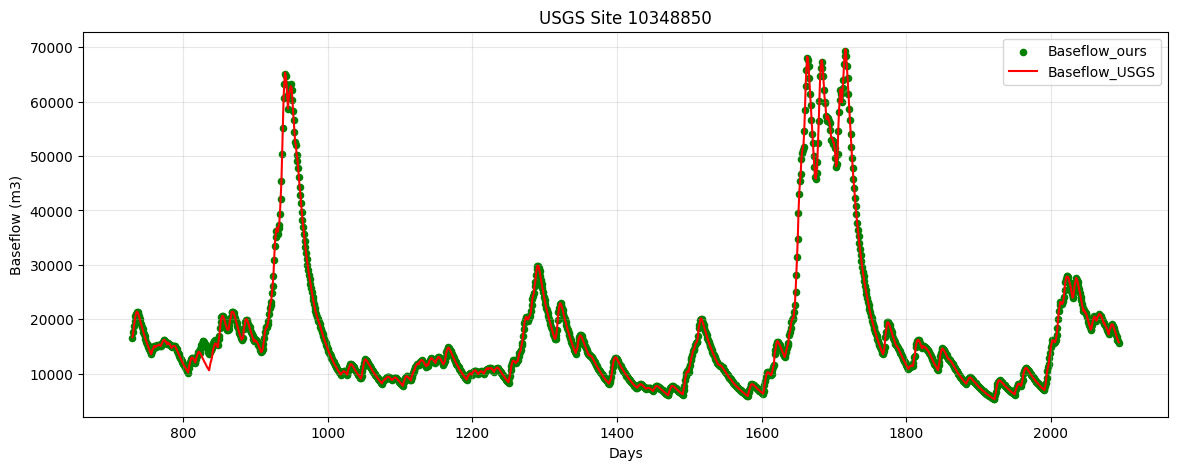

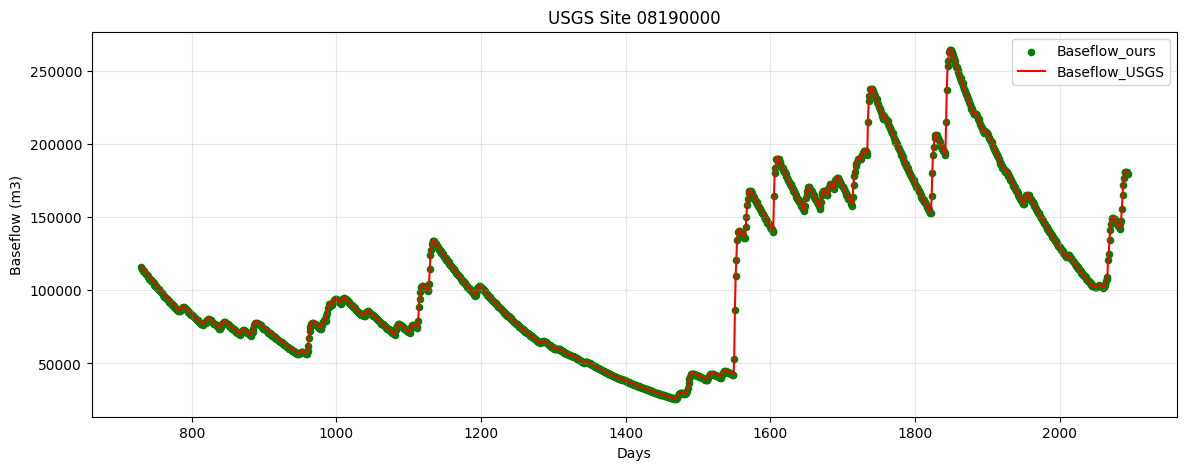

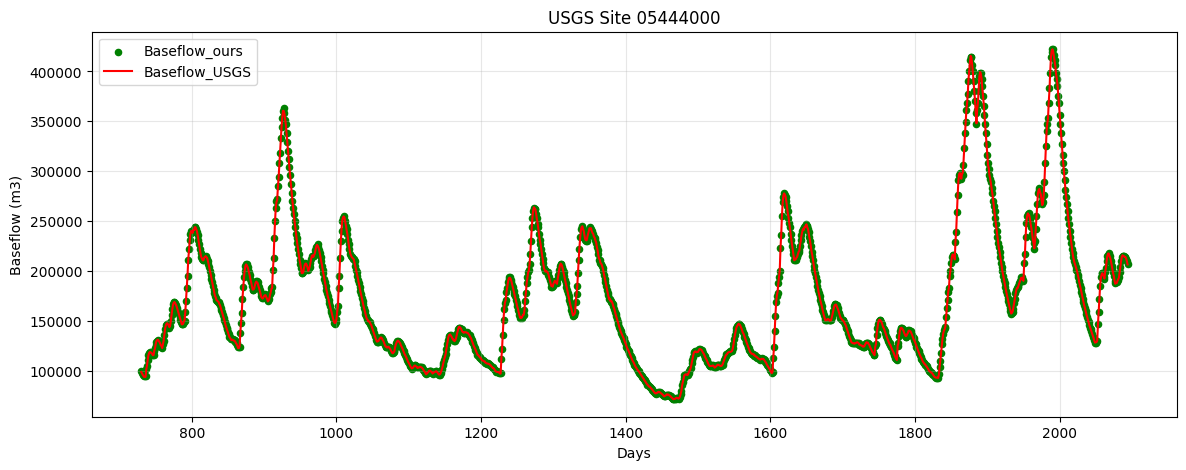

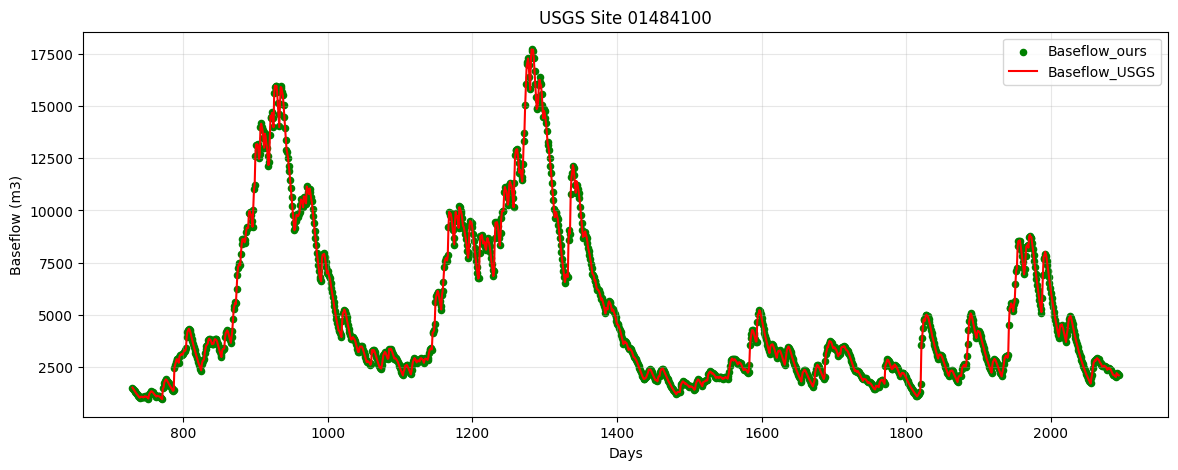

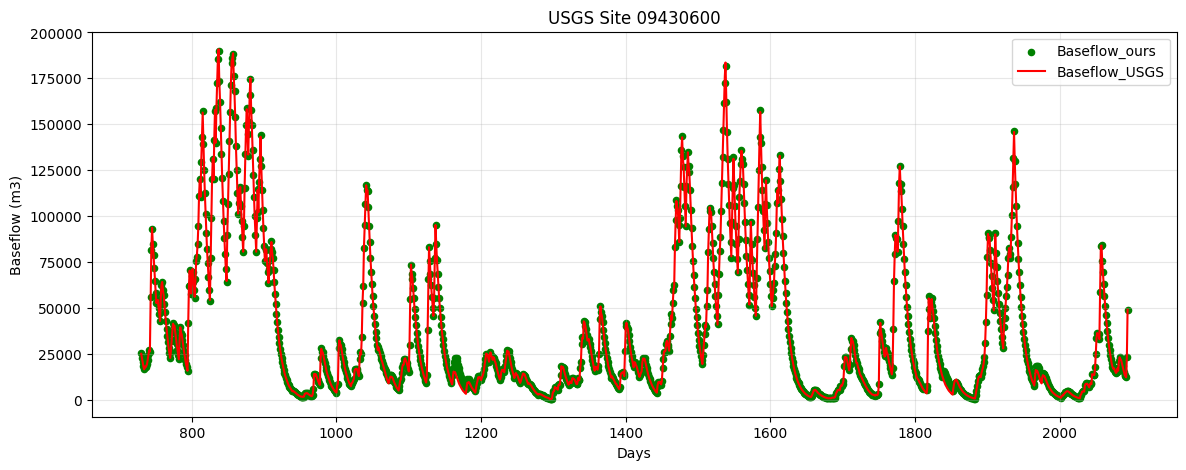

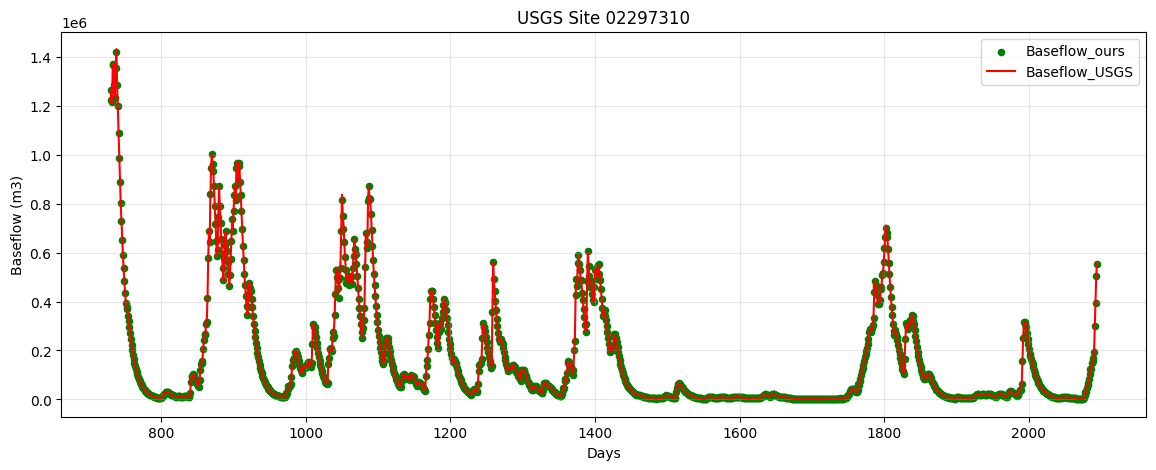

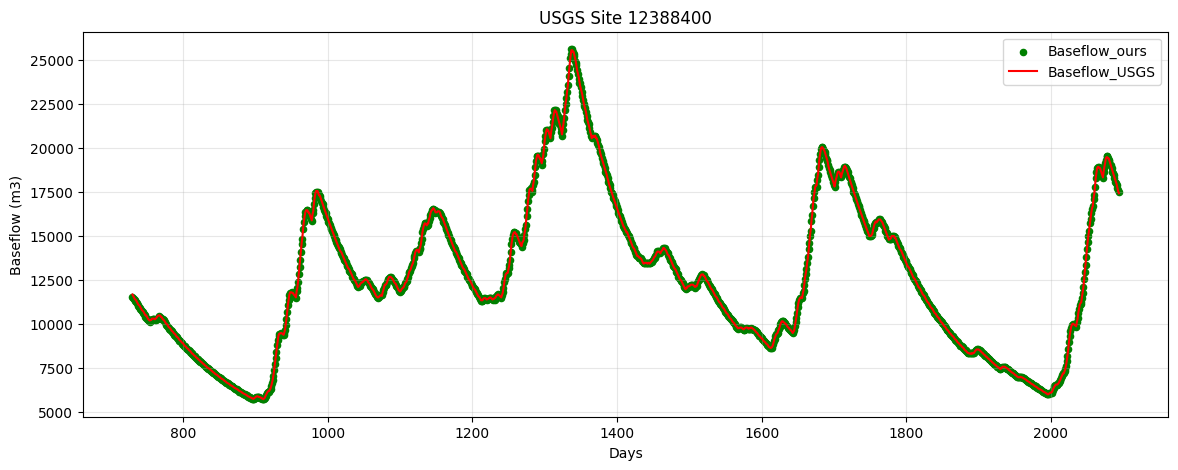

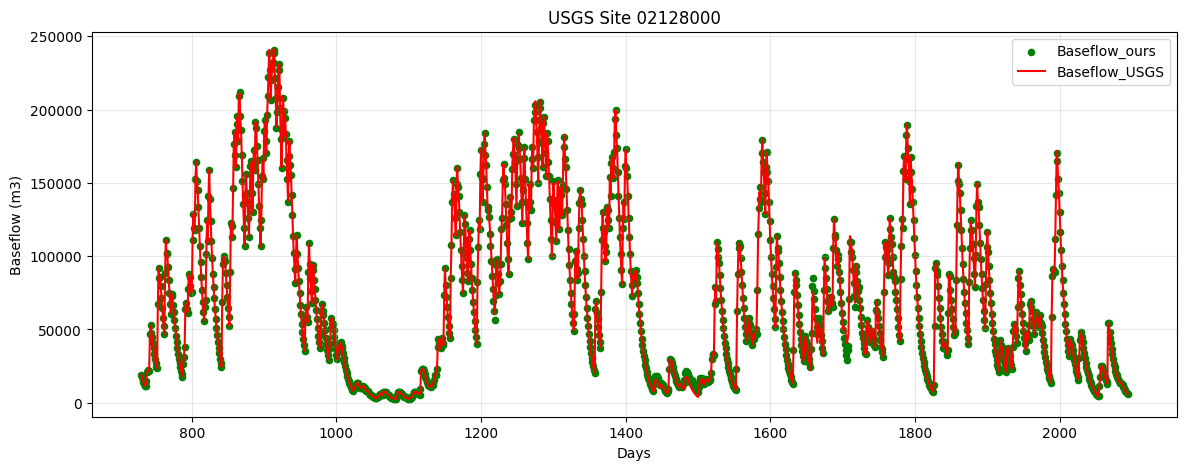

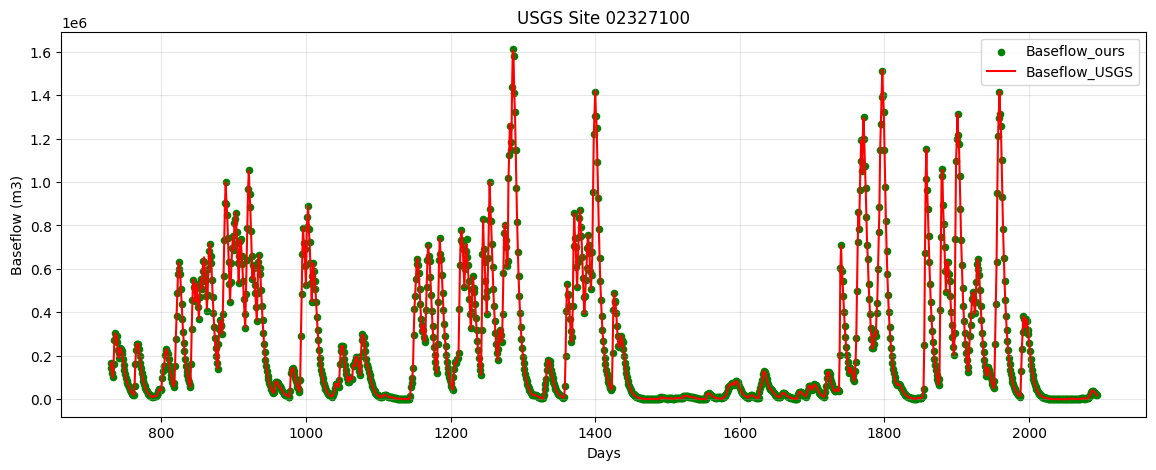

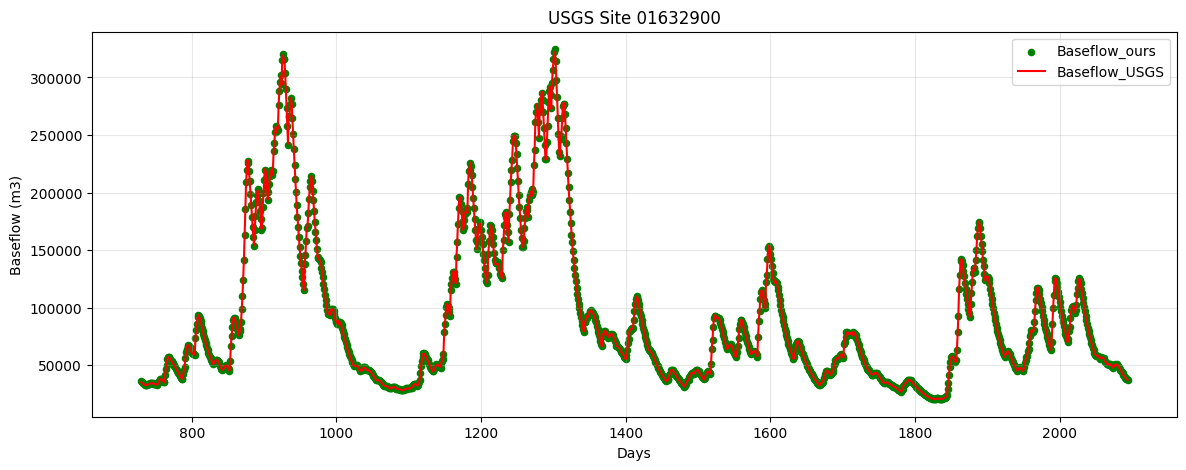

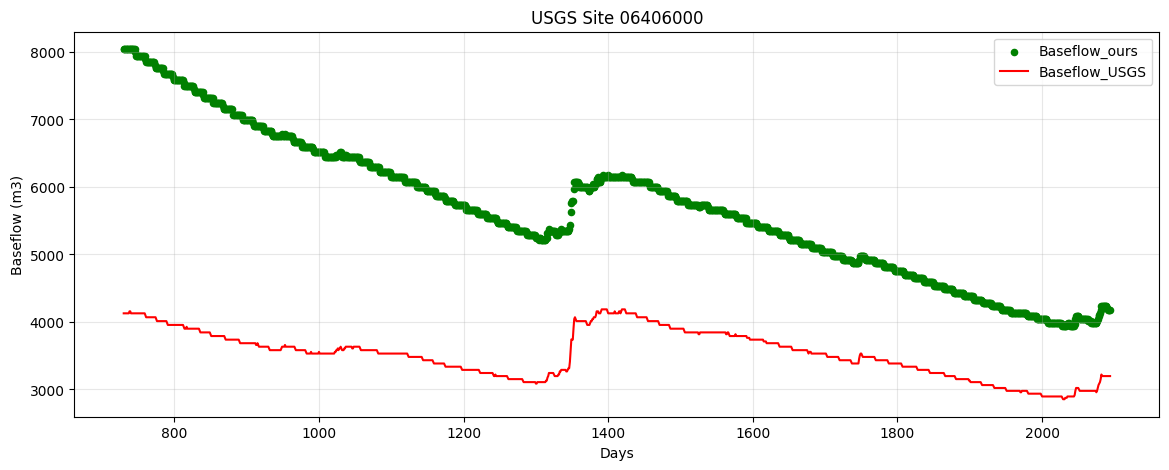

In [7]:
import pandas as pd
import matplotlib.pyplot as plt
import os

fol = "/home/s0shar47/scratch/USGS_baseflow/usgs_bfs/"
ofol = "/home/s0shar47/scratch/USGS_baseflow/Baseflow_669_sites/"

for file in os.listdir(fol)[0:20]:

    name = os.path.splitext(file)[0]

    # remove leading zeros
    usgs_name = str(int(name))

    try:
        dd1 = pd.read_csv(os.path.join(fol, f"{name}.csv"))
        dd2 = pd.read_csv(os.path.join(ofol, f"site_{usgs_name}.csv"))

        dd = pd.merge(dd1, dd2, how='inner', on='Date')

        dd.reset_index(drop=True, inplace=True)

        plt.figure(figsize=(14,5))

        plt.scatter(
            dd.iloc[730:2095].index,
            dd.iloc[730:2095]['Baseflow.L3'],
            label="Baseflow_ours",
            color="green",
            s=20
        )

        plt.plot(
            dd.iloc[730:2095]['Baseflow.M3'],
            label="Baseflow_USGS",
            color="red"
        )

        plt.title(f"USGS Site {name}")
        plt.xlabel("Days")
        plt.ylabel("Baseflow (m3)")
        plt.legend()
        plt.grid(alpha=0.3)
        plt.show()

    except FileNotFoundError:
        print(f"site_{usgs_name}.csv not found")

In [15]:
import os
import pandas as pd
import numpy as np
fol = "/home/s0shar47/scratch/USGS_baseflow/usgs_bfs/"

forcing= np.load("/scratch/data/CAMELS_FORCING/daymet_19800101_20141231_forcing_671_baseflow_mmday.npy")
gauges=[]
gids=[]
for i,file in enumerate(os.listdir(fol)):
    df= pd.read_csv(os.path.join(fol,file))
    gauge= float(os.path.splitext(file)[0])
    gauges.append(gauge)
    gids.append(forcing[i,0,-2])

common_elements = set(gauges).intersection(gids)

# 2. Get the count
count = len(common_elements)

print(count)


671


In [38]:
import os
import numpy as np
import pandas as pd
import shutil
import json

fol = "/home/s0shar47/scratch/USGS_baseflow/usgs_bfs_updated/"

attr_file = "/scratch/data/CAMELS_FORCING/daymet_19800101_20141231_attr_671.npy"
forcing_file = "/scratch/data/CAMELS_FORCING/daymet_19800101_20141231_forcing_671_baseflow_mmday.npy"
forc_json= "/scratch/data/CAMELS_FORCING/daymet_19800101_20141231_forcing_671_baseflow_mmday_name.json"

out_file = "/scratch/data/CAMELS_FORCING/daymet_19800101_20141231_forcing_671_usgs.npy"
out_json= "/scratch/data/CAMELS_FORCING/daymet_19800101_20141231_forcing_671_usgs_name.json"


# Load
forcing = np.load(forcing_file)
area_array = np.load(attr_file)[:, 11]

print("Original shape:", forcing.shape)

target_dates = pd.date_range(
    start="1980-01-01",
    end="2014-12-31",
    freq="D"
)

n_basins, n_days, n_features = forcing.shape

# Store USGS baseflow
usgs_baseflow = np.zeros(
    (n_basins, n_days),
    dtype=np.float32
)

# Gauge IDs
gauge_list = forcing[:, 0, -2].astype(int)


for i, gauge_id in enumerate(gauge_list):

    file_path = os.path.join(fol, f"{gauge_id}.csv")

    if not os.path.exists(file_path):
        print(f"Missing: {gauge_id}")
        continue

    df = pd.read_csv(file_path)

    df["Date"] = pd.to_datetime(df["Date"])
    df = df.set_index("Date")

    # Align dates
    df = df.reindex(target_dates)

    # Convert m3/day -> mm/day
    area_km2 = area_array[i]

    usgs_mmday = (
        df["Baseflow.L3"] / (area_km2 * 1000)
    )

    usgs_baseflow[i, :] = (
        usgs_mmday
        .fillna(0)
        .values
        .astype(np.float32)
    )

    print(f"{i+1}/{n_basins}: {gauge_id}")


# --------------------------------------------------
# Replace existing 16th variable
# index 15 = last feature
# --------------------------------------------------

forcing[:, :, 15] = usgs_baseflow


print("Updated shape:", forcing.shape)

# Copy the forcing variable names JSON
shutil.copy(forc_json, out_json)

print(f"Copied JSON to: {out_json}")
# Save
np.save(
    out_file,
    forcing
)

print("Saved:", out_file)

Original shape: (671, 12784, 16)
1/671: 1013500
2/671: 1022500
3/671: 1030500
4/671: 1031500
5/671: 1047000
6/671: 1052500
7/671: 1054200
8/671: 1055000
9/671: 1057000
10/671: 1073000
11/671: 1078000
12/671: 1118300
13/671: 1121000
14/671: 1123000
15/671: 1134500
16/671: 1137500
17/671: 1139000
18/671: 1139800
19/671: 1142500
20/671: 1144000
21/671: 1162500
22/671: 1169000
23/671: 1170100
24/671: 1181000
25/671: 1187300
26/671: 1195100
27/671: 1333000
28/671: 1350000
29/671: 1350080
30/671: 1350140
31/671: 1365000
32/671: 1411300
33/671: 1413500
34/671: 1414500
35/671: 1415000
36/671: 1423000
37/671: 1434025
38/671: 1435000
39/671: 1439500
40/671: 1440000
41/671: 1440400
42/671: 1451800
43/671: 1466500
44/671: 1484100
45/671: 1485500
46/671: 1486000
47/671: 1487000
48/671: 1491000
49/671: 1510000
50/671: 1516500
51/671: 1518862
52/671: 1532000
53/671: 1539000
54/671: 1542810
55/671: 1543000
56/671: 1543500
57/671: 1544500
58/671: 1545600
59/671: 1547700
60/671: 1548500
61/671: 1549500


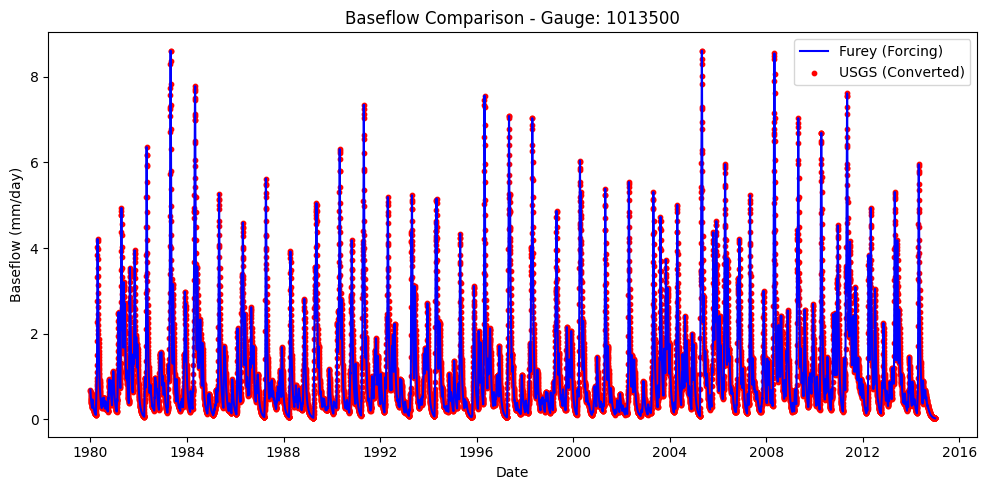

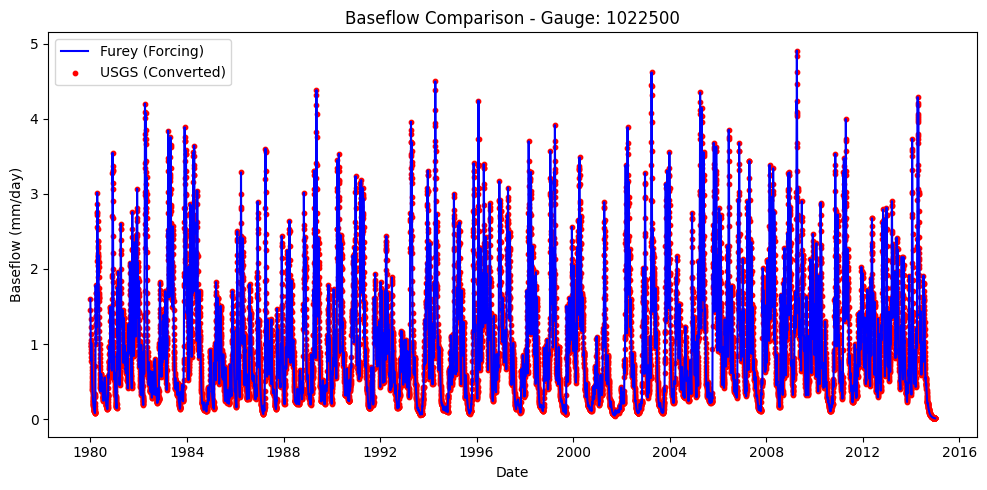

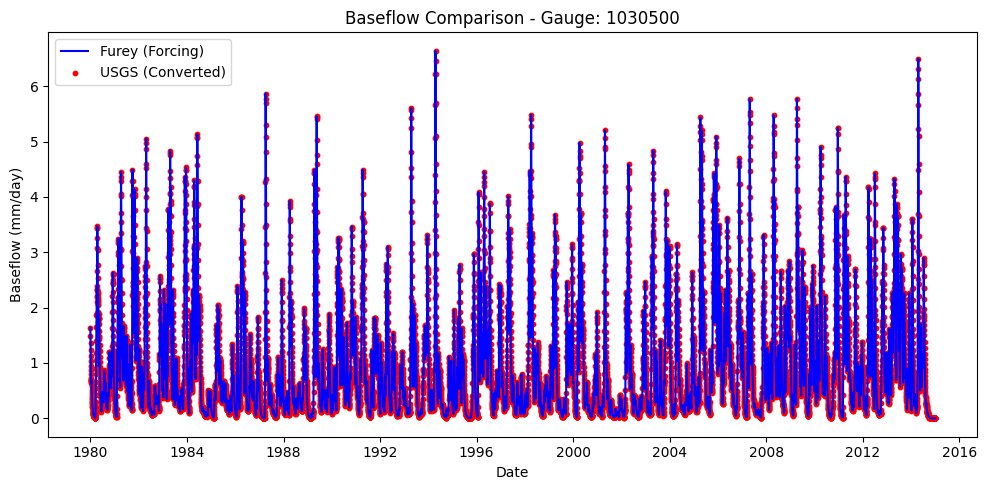

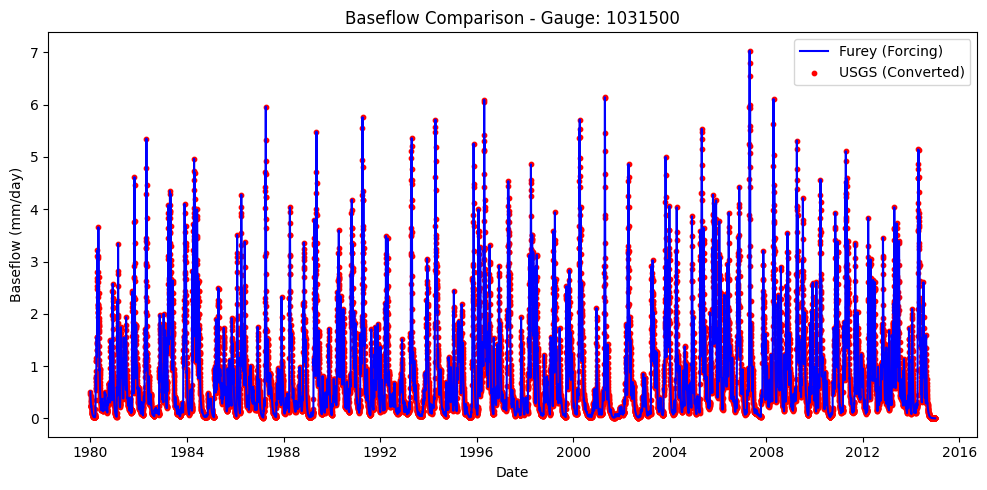

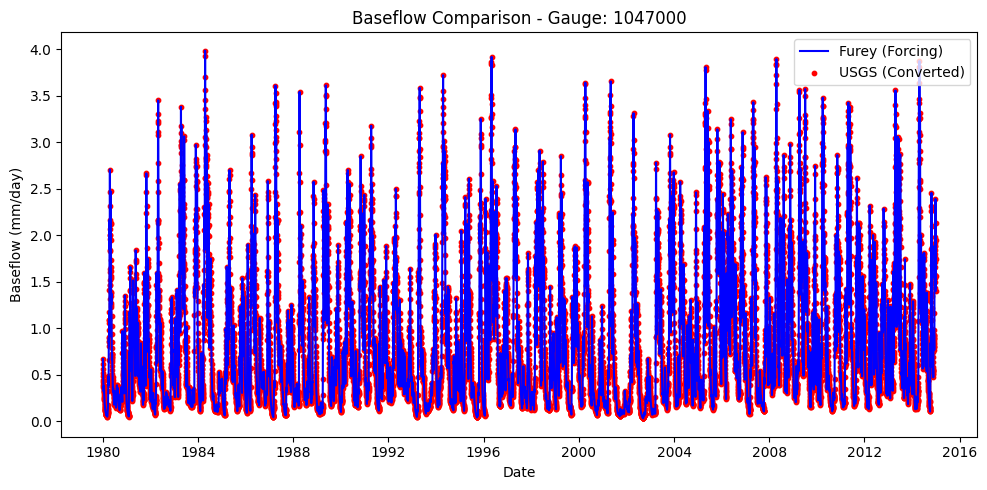

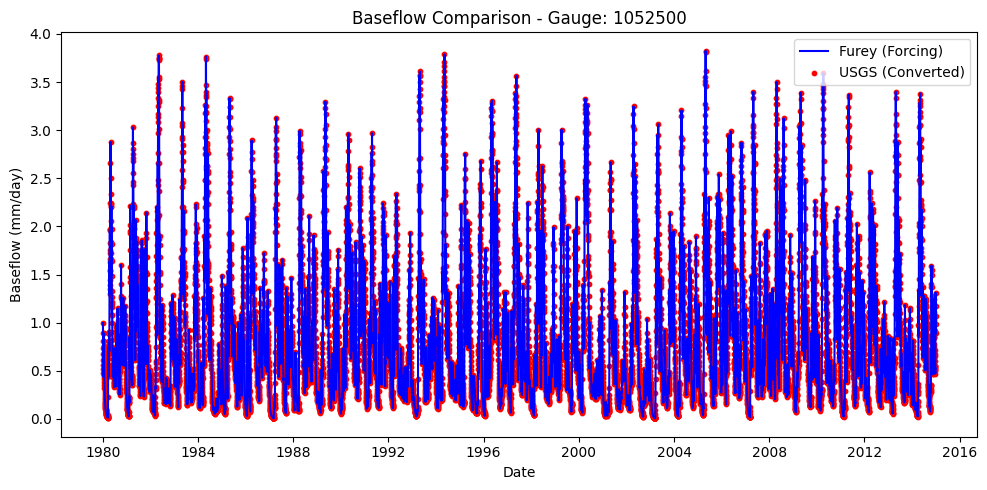

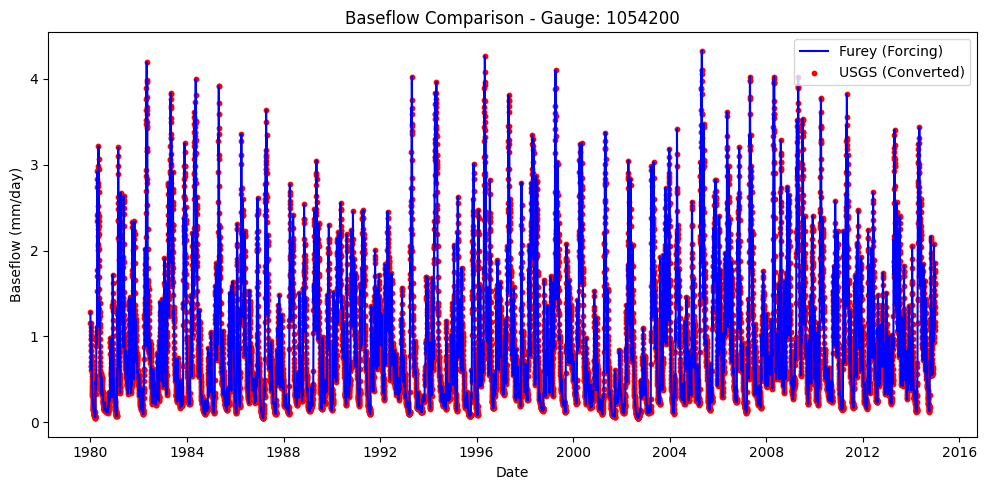

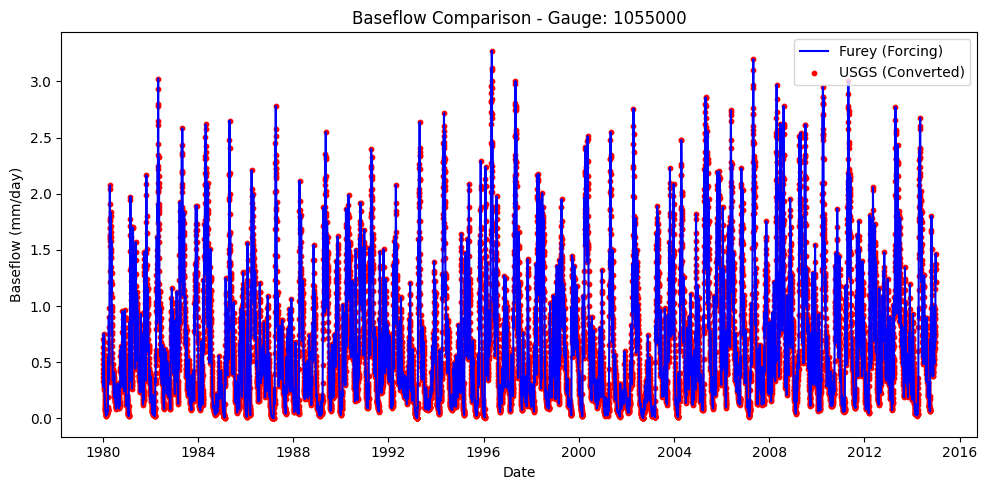

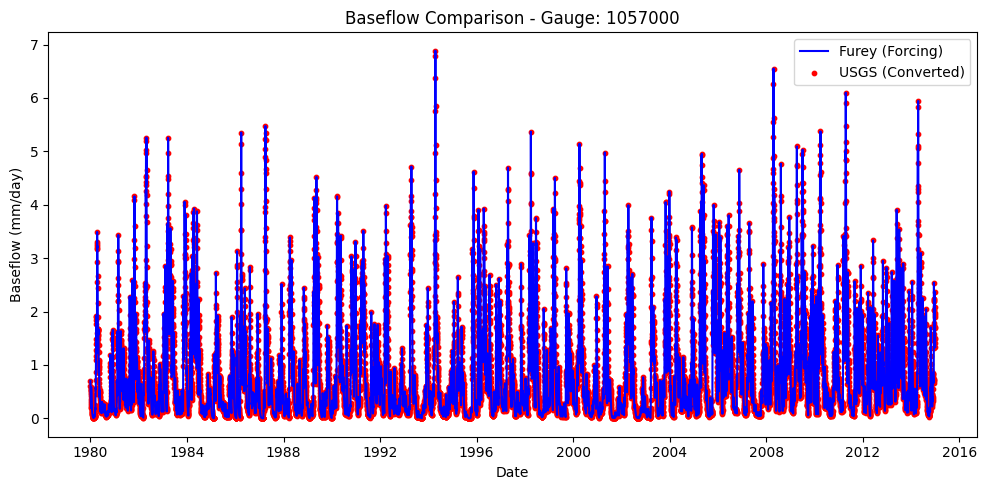

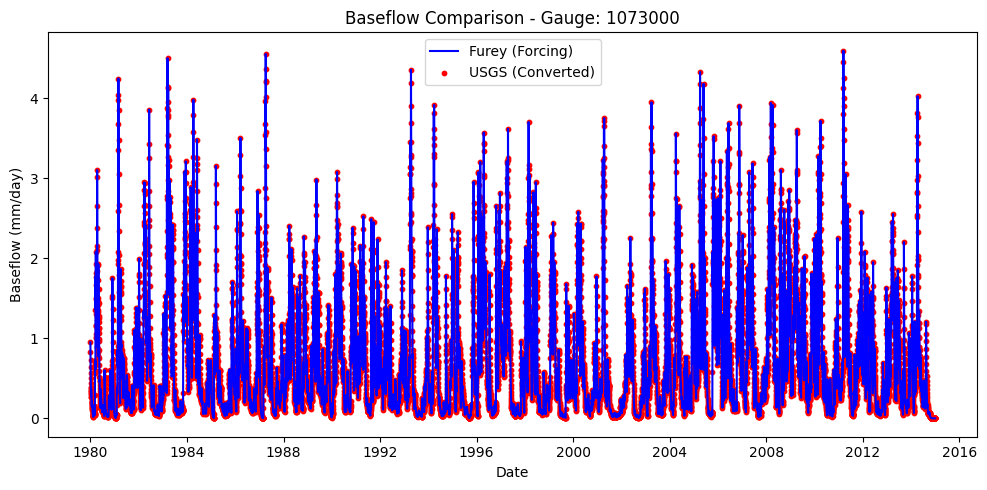

In [36]:
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

fol = "/home/s0shar47/scratch/USGS_baseflow/usgs_bfs_updated/"

# Load area attribute array (Shape: [671 basins]) -> values are in km^2
area_array = np.load(
    "/scratch/data/CAMELS_FORCING/daymet_19800101_20141231_attr_671.npy"
)[:, 11]

forcing = np.load(
    # "/scratch/data/CAMELS_FORCING/daymet_19800101_20141231_forcing_671_baseflow_mmday.npy"
        "/scratch/data/CAMELS_FORCING/daymet_19800101_20141231_forcing_671_usgs.npy"

)
target_dates = pd.date_range(start="1980-01-01", end="2014-12-31", freq="D")
master_df = pd.DataFrame(index=target_dates)

# Get the list of gauge IDs as integers
gauge_list = [int(g) for g in forcing[:, 0, -2].tolist()]

# Loop through the first 10 gauges
for i in range(10):
    gauge_id = gauge_list[i]
    baseflow_furey = forcing[i, :, -1]

    # Extract the corresponding area value (in km^2) for this specific basin
    basin_area_km2 = area_array[i]

    # Construct the file name string
    file = str(gauge_id)
    file_path = os.path.join(fol, file) + ".csv"

    # Quick check to bypass missing files safely
    if not os.path.exists(file_path):
        print(f"File missing: {file_path}. Skipping.")
        continue

    # Load data
    df = pd.read_csv(file_path)
    df["Date"] = pd.to_datetime(df["Date"])
    df.set_index("Date", inplace=True)
    df_extended = master_df.join(df, how="left")

    # =====================================================================
    # UNIT CONVERSION: m3/day to mm/day
    # =====================================================================
    # divide by (area * 1,000,000) for meters, then multiply by 1,000 for mm
    df_extended["Baseflow.L3_mmday"] = df_extended["Baseflow.L3"] / (
        basin_area_km2 * 1000
    )

    
    # =====================================================================

    # Generate the comparison plot
    plt.figure(figsize=(10, 5))
    plt.plot(
        target_dates, baseflow_furey, color="blue", label="Furey (Forcing)"
    )
    plt.scatter(
        df_extended.index,
        df_extended["Baseflow.L3_mmday"],  # Using converted values
        s=10,
        color="red",
        label="USGS (Converted)",
    )

    plt.title(f"Baseflow Comparison - Gauge: {file}")
    plt.xlabel("Date")
    plt.ylabel("Baseflow (mm/day)")
    plt.legend()
    plt.tight_layout()

    plt.show()
    plt.close()

In [26]:
import os
import pandas as pd
import numpy as np
fol = "/home/s0shar47/scratch/USGS_baseflow/usgs_bfs/"
nfol = "/home/s0shar47/scratch/USGS_baseflow/usgs_bfs_updated/"
os.makedirs(nfol, exist_ok=True)

for file in os.listdir(fol):
    df= pd.read_csv(os.path.join(fol,file))
    file_name= str(int(os.path.splitext(file)[0])) + '.csv'
    df.to_csv(os.path.join(nfol, file_name),index=False)

    print(file_name)

2342933.csv
5503800.csv
2069700.csv
2450250.csv
7184000.csv
11475560.csv
1435000.csv
6404000.csv
2011460.csv
10348850.csv
8190000.csv
5444000.csv
1484100.csv
9430600.csv
2297310.csv
12388400.csv
2128000.csv
2327100.csv
1632900.csv
6406000.csv
2059500.csv
2427250.csv
14308990.csv
3140000.csv
10336660.csv
9505350.csv
6885500.csv
7066000.csv
2198100.csv
2349900.csv
5593900.csv
10173450.csv
6191500.csv
3439000.csv
3285000.csv
2011400.csv
6408700.csv
4024430.csv
1545600.csv
8070000.csv
3069500.csv
4124000.csv
11523200.csv
7060710.csv
2096846.csv
6224000.csv
2235200.csv
12147500.csv
3500240.csv
12115500.csv
3010655.csv
3066000.csv
9107000.csv
3456500.csv
2143000.csv
9494000.csv
2464360.csv
7290650.csv
9065500.csv
1518862.csv
9034900.csv
4127997.csv
2231342.csv
12043000.csv
5495000.csv
3574500.csv
4115265.csv
9047700.csv
2178400.csv
2149000.csv
13018300.csv
14185000.csv
2013000.csv
6280300.csv
8175000.csv
11480390.csv
3238500.csv
12114500.csv
8029500.csv
11253310.csv
1591400.csv
2102908.csv
2